<a href="https://colab.research.google.com/github/rimitad70-jpg/Rimi-demo/blob/main/Lisence_Plate_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!apt-get update -qq
!apt-get install -y tesseract-ocr

!pip install opencv-python numpy matplotlib pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (5.3.4-1build5).
0 upgraded, 0 newly installed, 0 to remove and 67 not upgraded.


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
import re

from google.colab import files

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [ ]:
uploaded = files.upload()

filename = next(iter(uploaded))

print("Uploaded Image:", filename)

Saving image.png to image (2).png
Uploaded Image: image (2).png


Image Loaded Successfully!


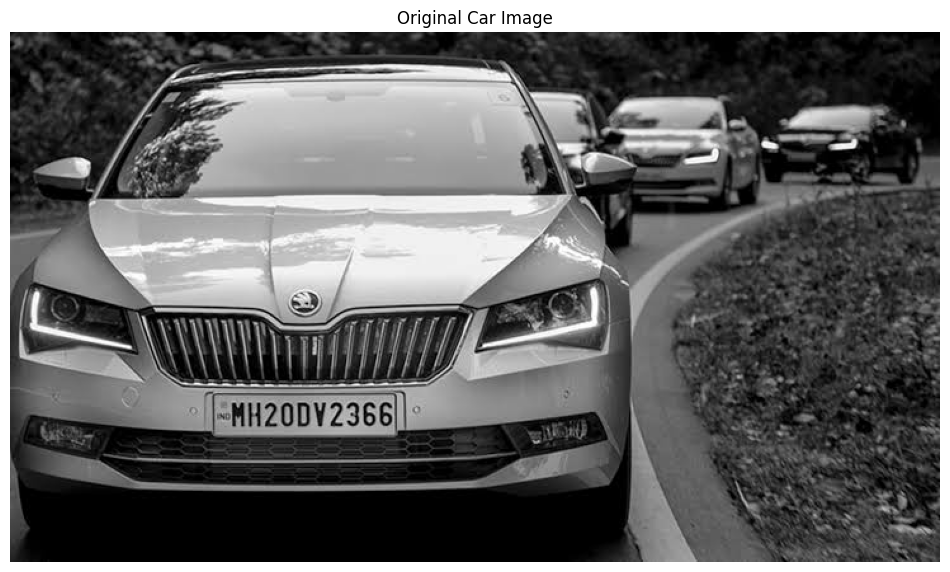

In [ ]:
image = cv2.imread(filename)

if image is None:
    print("Image Loading Failed!")
else:
    print("Image Loaded Successfully!")

    image_rgb = cv2.cvtColor(
        image, cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(12, 7))
    plt.imshow(image_rgb)
    plt.title("Original Car Image")
    plt.axis("off")
    plt.show()

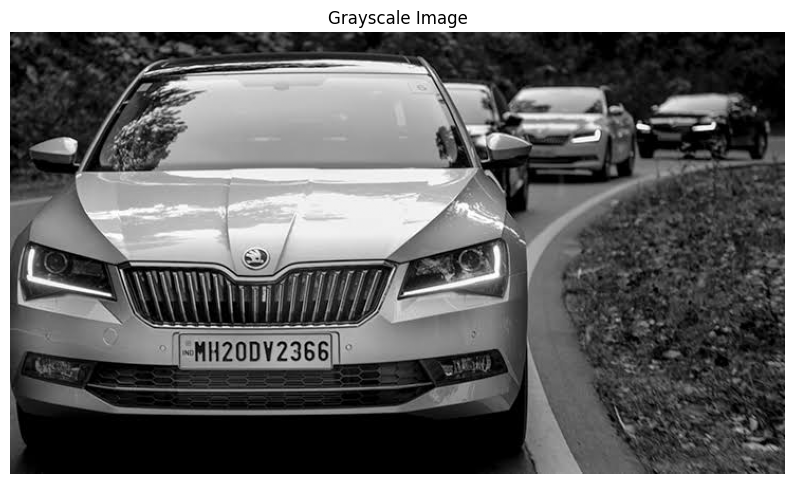

In [ ]:
gray_image = cv2.cvtColor(
    image, cv2.COLOR_BGR2GRAY
)

plt.figure(figsize=(10, 6))
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

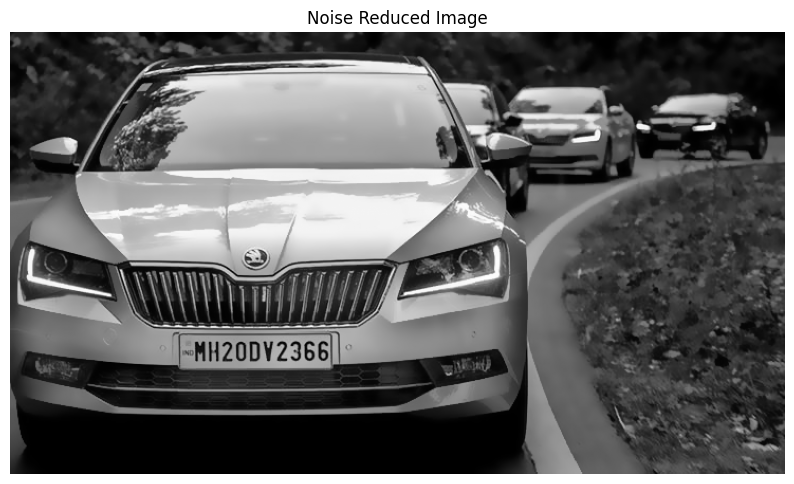

In [ ]:
blur_image = cv2.bilateralFilter(
    gray_image, 11, 17, 17
)

plt.figure(figsize=(10, 6))
plt.imshow(blur_image, cmap="gray")
plt.title("Noise Reduced Image")
plt.axis("off")
plt.show()

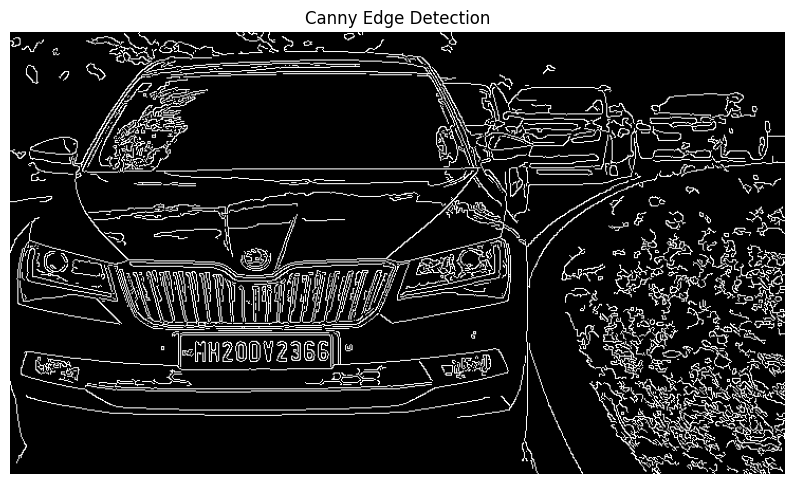

In [ ]:
edges = cv2.Canny(
    blur_image, 50, 150
)

plt.figure(figsize=(10, 6))
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")
plt.show()

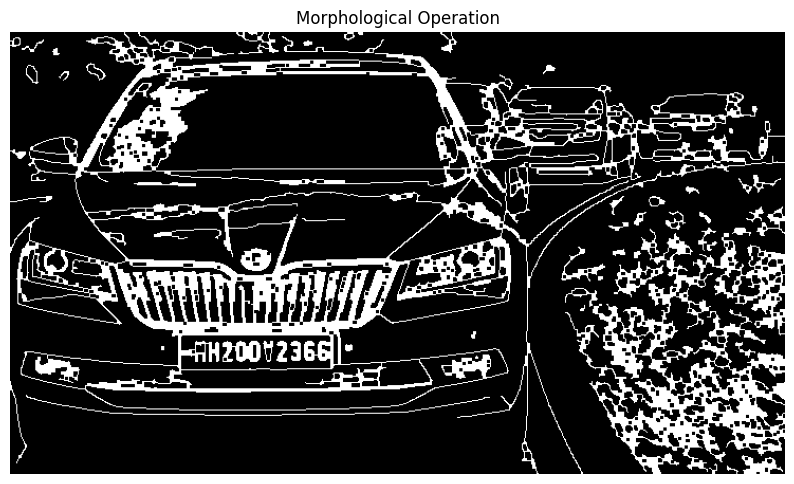

In [ ]:
kernel = np.ones((3, 3), np.uint8)

morph_image = cv2.morphologyEx(
    edges,
    cv2.MORPH_CLOSE,
    kernel
)

plt.figure(figsize=(10, 6))
plt.imshow(morph_image, cmap="gray")
plt.title("Morphological Operation")
plt.axis("off")
plt.show()

In [ ]:
contours, _ = cv2.findContours(
    morph_image,
    cv2.RETR_TREE,
    cv2.CHAIN_APPROX_SIMPLE
)

height, width = image.shape[:2]

plate_candidates = []

for contour in contours:

    x, y, w, h = cv2.boundingRect(contour)

    if h == 0:
        continue

    aspect_ratio = w / float(h)
    area = w * h

    if (
        2.0 <= aspect_ratio <= 6.5
        and w > width * 0.08
        and h > height * 0.015
        and area > 500
        and y + h < height
    ):
        plate_candidates.append((x, y, w, h))

print("Possible License Plates:", len(plate_candidates))

Possible License Plates: 16


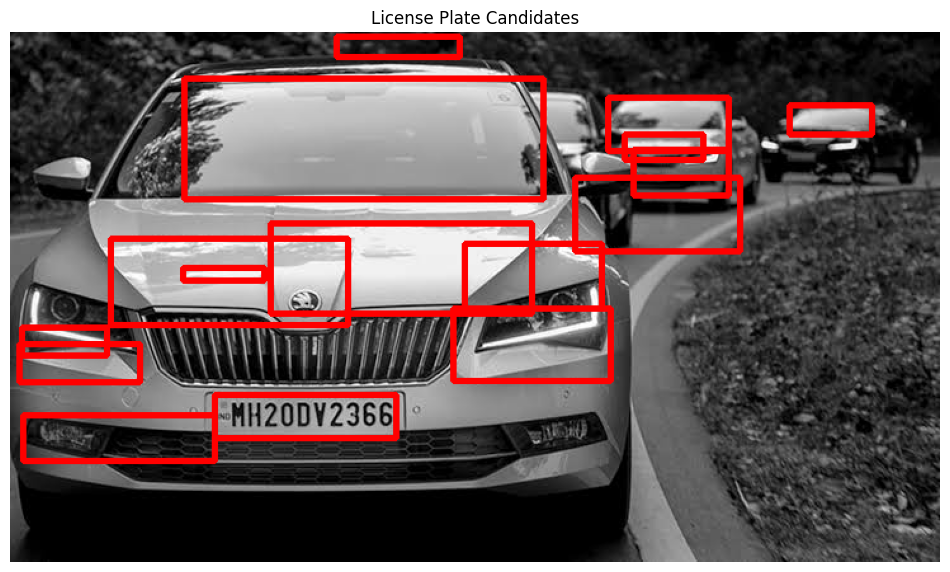

In [ ]:
result_image = image_rgb.copy()

for x, y, w, h in plate_candidates:

    cv2.rectangle(
        result_image,
        (x, y),
        (x + w, y + h),
        (255, 0, 0),
        3
    )

plt.figure(figsize=(12, 7))
plt.imshow(result_image)
plt.title("License Plate Candidates")
plt.axis("off")
plt.show()

In [ ]:
import pytesseract

print("Tesseract Version:")
print(pytesseract.get_tesseract_version())

Tesseract Version:
5.3.4


In [ ]:
ocr_results = []

for x, y, w, h in plate_candidates:

    plate_crop = gray_image[y:y+h, x:x+w]

    # Resize image
    plate_crop = cv2.resize(
        plate_crop, None,
        fx=3, fy=3,
        interpolation=cv2.INTER_CUBIC
    )

    # Apply threshold
    processed = cv2.threshold(
        plate_crop, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )[1]

    config = '--oem 3 --psm 7 -c tessedit_char_whitelist=ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789'

    text = pytesseract.image_to_string(
        processed,
        config=config
    )

    clean_text = re.sub(r'[^A-Z0-9]', '', text.upper())

    print("Detected Number:", clean_text)

    if clean_text:
        ocr_results.append(clean_text)

Detected Number: ZG
Detected Number: ST
Detected Number: MH20DV2366
Detected Number: SN
Detected Number: 
Detected Number: 
Detected Number: 
Detected Number: 
Detected Number: 
Detected Number: 
Detected Number: 
Detected Number: 
Detected Number: PD
Detected Number: 
Detected Number: 
Detected Number: A


In [ ]:
pattern = r'^[A-Z]{2}[0-9]{2}[A-Z]{1,2}[0-9]{4}$'

valid_results = []
invalid_results = []

for number in ocr_results:

    number = number.strip().upper()

    if re.fullmatch(pattern, number):
        valid_results.append(number)
        print("VALID:", number)

    else:
        invalid_results.append(number)
        print("INVALID:", number)

print("\nTotal Valid:", len(valid_results))
print("Total Invalid:", len(invalid_results))

INVALID: ZG
INVALID: ST
VALID: MH20DV2366
INVALID: SN
INVALID: PD
INVALID: A

Total Valid: 1
Total Invalid: 5


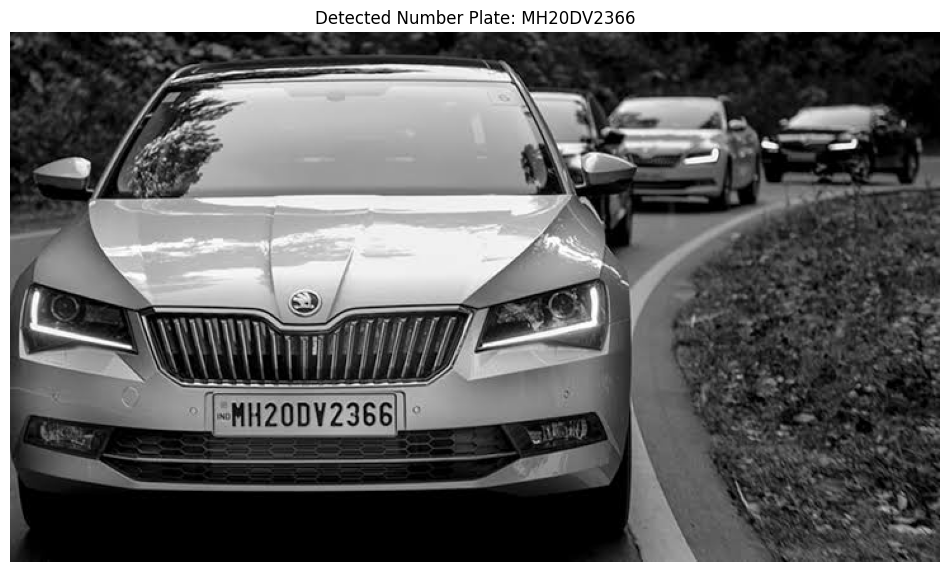

FINAL REGISTRATION NUMBER: MH20DV2366


In [ ]:
final_image = image_rgb.copy()

if valid_results:

    plate_number = valid_results[0]

    plt.figure(figsize=(12, 7))
    plt.imshow(final_image)
    plt.title("Detected Number Plate: " + plate_number)
    plt.axis("off")
    plt.show()

    print("FINAL REGISTRATION NUMBER:", plate_number)

else:
    print("No valid number plate found.")

In [ ]:
import re

pattern = r'^[A-Z]{2}\d{1,2}[A-Z]{1,3}\d{4}$'

test = "GJO3ER0563"

print("Test Number:", test)
print("Validation:", re.fullmatch(pattern, test))

Test Number: GJO3ER0563
Validation: None
